# Day-ahead prediction results

Run this notebook after a training experiment finishes. For rolling-origin runs, it loads saved predictions and plots one selected held-out week; for older single-split runs, it rebuilds the held-out predictions from recorded Delta versions.


In [13]:
import json
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.lightgbm
from mlflow.tracking import MlflowClient

# VS Code uses the package installed by uv; a Databricks workspace notebook uses its synced source tree.
try:
    from eu_electricity_forecast.training import _features, _seasonal_baseline, _validate_and_prepare, _weekly_lag_comparison, _weekly_lag_predictions, chronological_split, load_training_frame
except ModuleNotFoundError as exc:
    if exc.name != "eu_electricity_forecast":
        raise
    notebook_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
    repo_root = notebook_path.split("/src/notebooks/", 1)[0]
    sys.path.insert(0, os.path.join(repo_root, "src"))
    from eu_electricity_forecast.training import _features, _seasonal_baseline, _validate_and_prepare, _weekly_lag_comparison, _weekly_lag_predictions, chronological_split, load_training_frame

# Databricks notebooks provide spark; local VS Code runs use the authenticated CLI profile.
if "spark" not in globals():
    from databricks.connect import DatabricksSession
    connect_profile = os.environ.get("DATABRICKS_CONFIG_PROFILE", "dev")
    if os.environ.get("DATABRICKS_AUTH_TYPE") == "metadata-service":
        os.environ.pop("DATABRICKS_AUTH_TYPE", None)
        os.environ.pop("DATABRICKS_METADATA_SERVICE_URL", None)
    os.environ["DATABRICKS_CONFIG_PROFILE"] = connect_profile
    spark = DatabricksSession.builder.profile(connect_profile).getOrCreate()

mlflow.set_tracking_uri("databricks")
current_user = spark.sql("SELECT current_user()").first()[0]
EXPERIMENT_PATH = f"/Users/{current_user}/eu-electricity-forecast-day-ahead-price"
client = MlflowClient()
experiment = client.get_experiment_by_name(EXPERIMENT_PATH)
if experiment is None:
    raise ValueError(f"MLflow experiment not found: {EXPERIMENT_PATH}")
runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="attributes.status = 'FINISHED'",
    order_by=["attributes.start_time DESC"],
    max_results=1,
)
if not runs:
    raise ValueError(f"No completed training runs found in {EXPERIMENT_PATH}")
selected_run = runs[0]
evaluation_strategy = selected_run.data.params.get("evaluation_strategy", "single_split")
if evaluation_strategy == "rolling_origin":
    summary_path = client.download_artifacts(selected_run.info.run_id, "rolling_experiment_summary.json")
    with open(summary_path) as summary_file:
        run_summary = json.load(summary_file)
    predictions_path = client.download_artifacts(selected_run.info.run_id, "rolling_predictions.csv")
    all_predictions = pd.read_csv(predictions_path, parse_dates=["target_interval_start_utc"])
    all_predictions["target_interval_start_utc"] = pd.to_datetime(all_predictions["target_interval_start_utc"], utc=True)
    if "weekly_lag_baseline_prediction" not in all_predictions:
        # Older rolling runs did not save this benchmark. Rebuild it from the
        # exact feature-table version used by that run.
        source_frame = load_training_frame(
            spark,
            run_summary["source_table"],
            run_summary["series_by_zone"],
            int(selected_run.data.params["resolution_minutes"]),
            run_summary["source_delta_versions"],
        )
        source_frame = _validate_and_prepare(
            source_frame, run_summary["series_by_zone"], int(selected_run.data.params["resolution_minutes"])
        )
        join_columns = ["bidding_zone", "target_interval_start_utc", "target_auction_series_key"]
        lag_columns = join_columns + ["price_lag_168h_eur_mwh", "price_lag_168h_eur_mwh_present"]
        lag_columns = [column for column in lag_columns if column in source_frame]
        all_predictions = all_predictions.merge(
            source_frame[lag_columns], on=join_columns, how="left", validate="one_to_one"
        )
        all_predictions["weekly_lag_baseline_prediction"] = _weekly_lag_predictions(all_predictions).to_numpy()
    available_fold_ids = sorted(all_predictions["fold_id"].astype(int).unique())
    FOLD_ID = available_fold_ids[0]  # Change this to inspect a different held-out week.
    test_predictions = all_predictions[all_predictions["fold_id"].astype(int) == FOLD_ID].copy()
    print(f"Rolling backtest fold {FOLD_ID} of {len(available_fold_ids)}")
    print(f"Week: {test_predictions['fold_start_utc'].iloc[0]} to {test_predictions['fold_end_exclusive_utc'].iloc[0]}")
    weekly = _weekly_lag_comparison(all_predictions)
    print(f"168-hour lag available for {weekly['rows']:,} of {run_summary['pooled_metrics']['rows']:,} held-out rows ({weekly['coverage']:.1%})")
    zone_rows = []
    for zone, metrics in weekly["by_zone"].items():
        zone_rows.append({
            "zone": zone,
            "lag rows": metrics["rows"],
            "LightGBM MAE (same rows)": metrics["model"]["mae"],
            "Seasonal median MAE (same rows)": metrics["seasonal_baseline"]["mae"],
            "168-hour lag MAE": metrics["weekly_lag_baseline"]["mae"],
        })
    display(pd.DataFrame(zone_rows).set_index("zone"))
else:
    summary_path = client.download_artifacts(selected_run.info.run_id, "experiment_summary.json")
    with open(summary_path) as summary_file:
        run_summary = json.load(summary_file)
    training_frame = load_training_frame(
        spark,
        run_summary["source_table"],
        run_summary["series_by_zone"],
        int(selected_run.data.params["resolution_minutes"]),
        run_summary["source_delta_versions"],
    )
    training_frame = _validate_and_prepare(
        training_frame, run_summary["series_by_zone"], int(selected_run.data.params["resolution_minutes"])
    )
    partitions, _ = chronological_split(training_frame)
    train_frame, test_frame = partitions["train"], partitions["test"]
    zone_categories = sorted(train_frame["bidding_zone"].dropna().unique().tolist())
    test_features, _ = _features(test_frame, zone_categories)
    logged_model = mlflow.lightgbm.load_model(f"runs:/{selected_run.info.run_id}/model")
    test_predictions = test_frame[
        ["bidding_zone", "target_interval_start_utc", "label_price_eur_mwh", "target_auction_series_key"]
    ].copy()
    test_predictions["model_prediction"] = logged_model.predict(test_features)
    test_predictions["seasonal_baseline_prediction"] = _seasonal_baseline(train_frame, test_frame)
    test_predictions["weekly_lag_baseline_prediction"] = _weekly_lag_predictions(test_frame).to_numpy()
    test_predictions["target_interval_start_utc"] = pd.to_datetime(test_predictions["target_interval_start_utc"], utc=True)

print(f"MLflow run: {selected_run.info.run_id}")
print(f"Evaluation: {evaluation_strategy}; rows in selected window: {len(test_predictions):,}")
print(f"Zones: {sorted(test_predictions['bidding_zone'].unique())}")


MLflow run: 3208d46a10134982a5ed8295a5b5939c
Resolution: 15 minutes
Test rows: 22,772; zones: ['DE_LU', 'FR', 'LT', 'NL']


,model,test MAE (€/MWh)
0,LightGBM,65.611791
1,Seasonal baseline,93.375144


## Actual prices and predictions by zone

For a rolling run, set `FOLD_ID` in the first cell to inspect another held-out week. The plots show LightGBM, the seasonal median (same zone, local weekday, and hour, pooled across months), and the 168-hour lag (same-series price exactly one week earlier). MAE captions compare all three on the same rows where the weekly lag is present; the plot shows the full week, with gaps in the lag line where it is missing. Each zone has its own price scale.


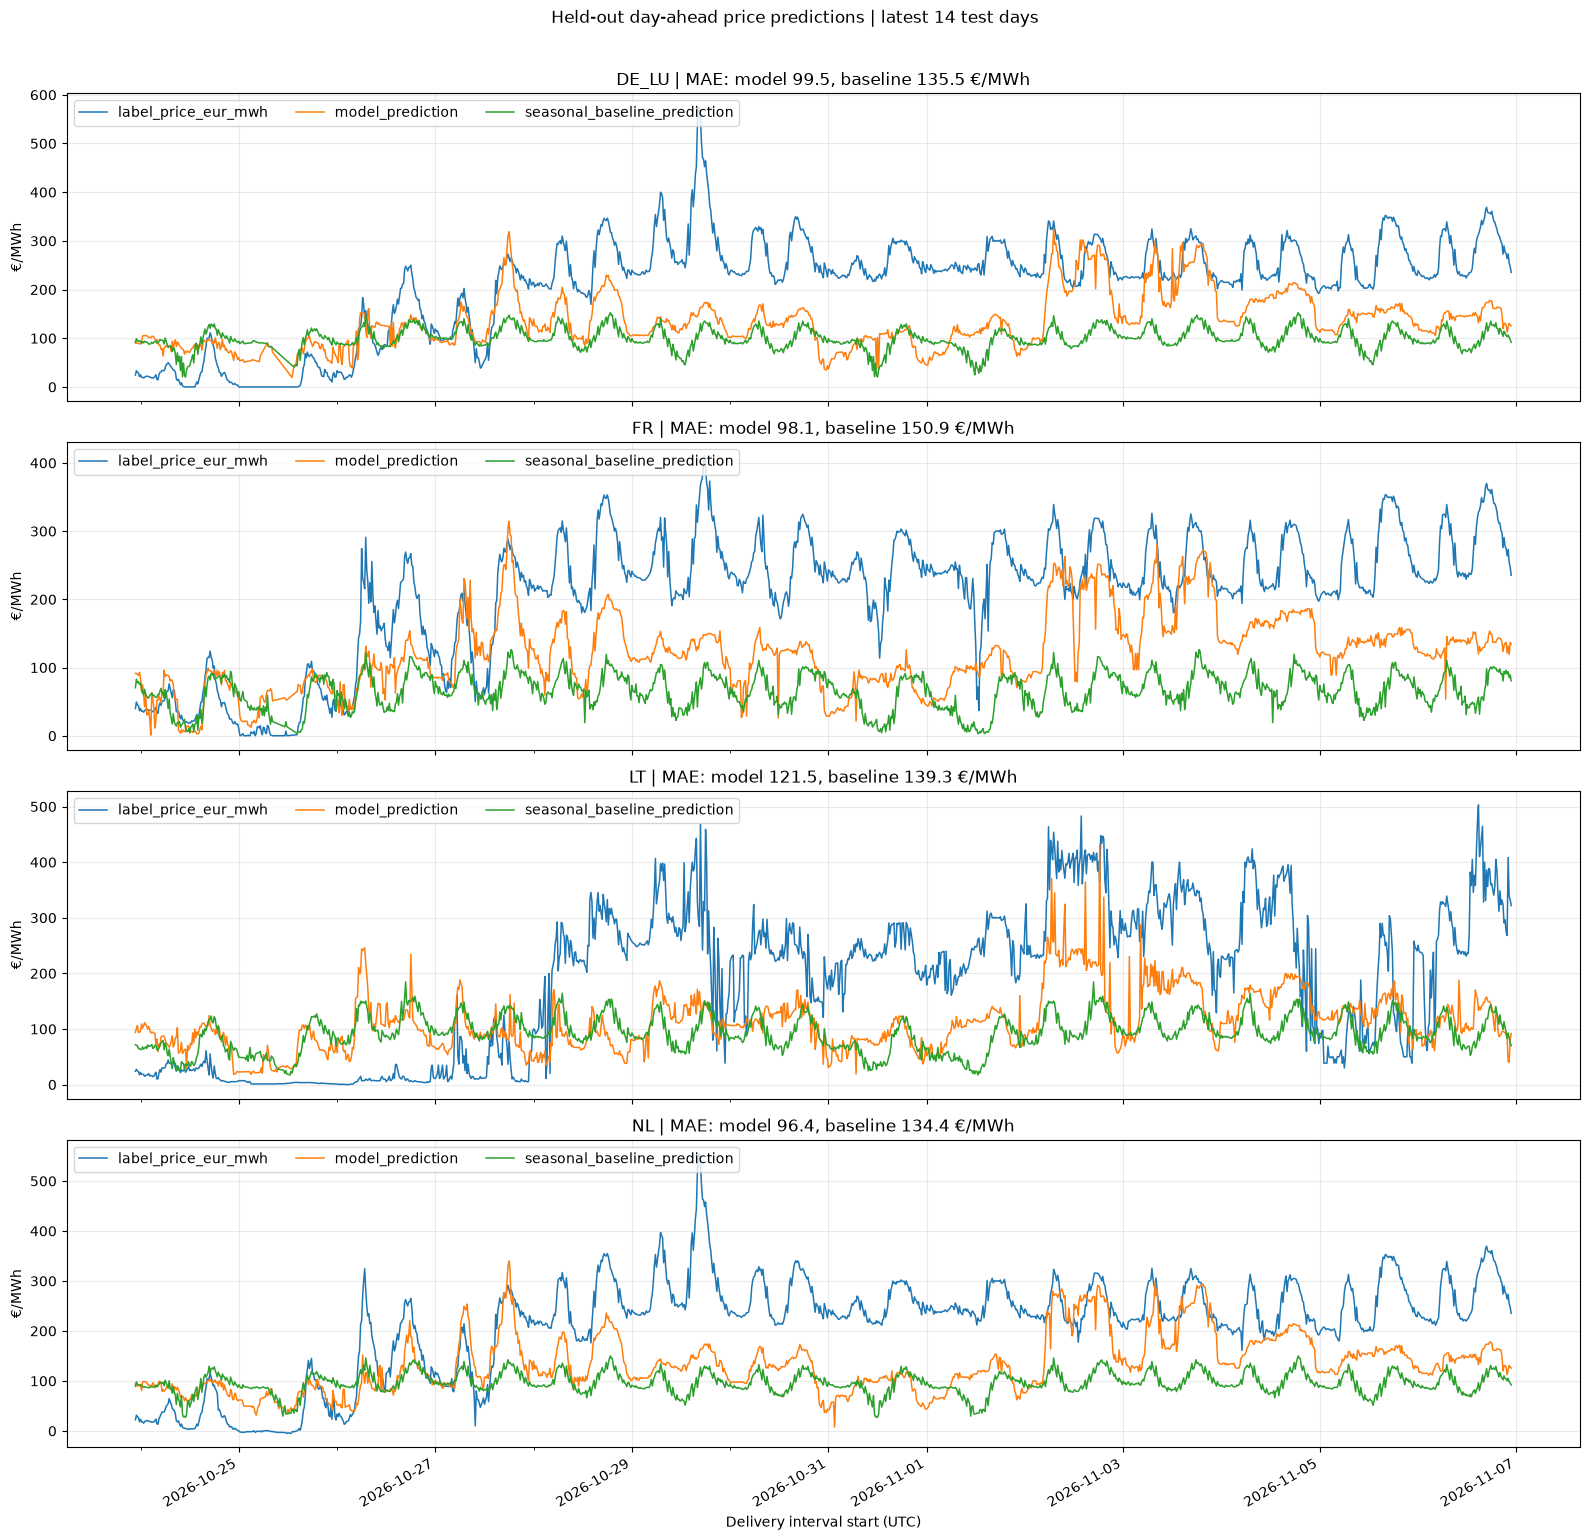

In [14]:
FIRST_TEST_TIME = test_predictions["target_interval_start_utc"].min()
zones = sorted(test_predictions["bidding_zone"].dropna().unique())

def plot_test_window(days, title):
    window_end = FIRST_TEST_TIME + pd.Timedelta(days=days)
    fig, axes = plt.subplots(len(zones), 1, figsize=(16, 3.8 * len(zones)), sharex=True, squeeze=False)

    for zone, ax in zip(zones, axes[:, 0]):
        chart = (
            test_predictions[
                (test_predictions["bidding_zone"] == zone)
                & (test_predictions["target_interval_start_utc"] >= FIRST_TEST_TIME)
                & (test_predictions["target_interval_start_utc"] < window_end)
            ]
            .sort_values("target_interval_start_utc")
            .set_index("target_interval_start_utc")
        )
        common_rows = chart.dropna(subset=["weekly_lag_baseline_prediction"])
        model_mae_common = (common_rows["model_prediction"] - common_rows["label_price_eur_mwh"]).abs().mean()
        seasonal_mae_common = (
            common_rows["seasonal_baseline_prediction"] - common_rows["label_price_eur_mwh"]
        ).abs().mean()
        weekly_mae_common = (
            common_rows["weekly_lag_baseline_prediction"] - common_rows["label_price_eur_mwh"]
        ).abs().mean()
        chart.rename(columns={
            "label_price_eur_mwh": "Actual price",
            "model_prediction": "LightGBM",
            "seasonal_baseline_prediction": "Seasonal median (zone/weekday/hour)",
            "weekly_lag_baseline_prediction": "168-hour lag",
        })[["Actual price", "LightGBM", "Seasonal median (zone/weekday/hour)", "168-hour lag"]].plot(
            ax=ax, linewidth=1.1,
            title=(
                f"{zone} | common-row MAE: model {model_mae_common:.1f}, "
                f"seasonal {seasonal_mae_common:.1f}, weekly lag {weekly_mae_common:.1f} €/MWh "
                f"(n={len(common_rows):,})"
            ),
        )
        if chart.empty:
            ax.text(0.5, 0.5, "No test intervals in this window", ha="center", va="center", transform=ax.transAxes)
        ax.set_xlim(FIRST_TEST_TIME, window_end)
        ax.set_ylabel("€/MWh")
        ax.grid(True, alpha=0.25)
        ax.legend(loc="upper left", ncol=4)

    axes[-1, 0].set_xlabel("Delivery interval start (UTC)")
    fig.suptitle(title, y=1.01)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

selected_window_label = f"rolling fold {FOLD_ID}" if "FOLD_ID" in globals() else "test period"
plot_test_window(7, f"Held-out predictions | {selected_window_label} | first 7 days")
plot_test_window(1, f"Held-out predictions | {selected_window_label} | first 24 hours")